# Experiment 10: Intelligent Decision Support System

**Application:** Student Academic Support Recommendation System  
**Methods:** Rule-based expert system, imitation learning, explanation facility, ethical/fairness audit, and before/after comparison.

## Scenario
A college wants to recommend one of three support actions to students who may need help:
- **Self-study plan**
- **Peer tutoring**
- **Academic advisor**

This is a teaching demonstration using **synthetic data only**. It is not a real student assessment tool. Recommendations should support—not replace—human judgment.

### Learning outcomes
1. Build a small knowledge base and rule-based inference engine.
2. Create human-labeled example decisions and train a model to imitate them.
3. Explain recommendations using fired rules and important input factors.
4. Audit outcomes across groups and discuss fairness/transparency.
5. Change a rule and the human examples, then compare the recommendations before and after.


## Task 0 — Import libraries and define the example data

We use ordinary Python, pandas, scikit-learn, and matplotlib. The data are generated in the notebook, so no download or API key is required.

**Input factors**
- `attendance`: percentage of classes attended
- `assignment_avg`: average assignment score out of 100
- `quiz_avg`: average quiz score out of 100
- `study_hours`: approximate independent study hours per week
- `group`: a synthetic group label used **only for fairness auditing**, not as a model feature

The `human_decision` column represents decisions supplied by a hypothetical human advisor. We intentionally include a small group-dependent pattern in the first version so the fairness audit has something meaningful to detect.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

SEED = 42
rng = np.random.default_rng(SEED)

ACTIONS = ["Self-study plan", "Peer tutoring", "Academic advisor"]

def human_label(attendance, assignment_avg, quiz_avg, study_hours, group, biased=True):
    """Simulate a human advisor's example decision.

    The baseline rule uses academic indicators. For demonstration only, when
    biased=True, Group B receives a slightly more severe decision in borderline
    cases. This is intentionally included to demonstrate how unfair patterns
    can enter example labels. Do not use group membership for real decisions.
    """
    academic_score = 0.30 * attendance + 0.35 * assignment_avg + 0.35 * quiz_avg
    low_support_signal = (
        attendance < 65 or assignment_avg < 50 or quiz_avg < 50
    )
    borderline = academic_score < 62 or study_hours < 4

    if low_support_signal:
        decision = "Academic advisor"
    elif borderline:
        decision = "Peer tutoring"
    else:
        decision = "Self-study plan"

    # Deliberate synthetic bias: only used in the baseline human examples.
    if biased and group == "Group B" and decision == "Self-study plan" and academic_score < 72:
        decision = "Peer tutoring"

    return decision

n = 600
df = pd.DataFrame({
    "attendance": rng.integers(40, 101, size=n),
    "assignment_avg": np.clip(rng.normal(68, 17, size=n), 15, 100).round(1),
    "quiz_avg": np.clip(rng.normal(65, 18, size=n), 10, 100).round(1),
    "study_hours": np.clip(rng.normal(7, 3, size=n), 0, 20).round(1),
    "group": rng.choice(["Group A", "Group B"], size=n, p=[0.5, 0.5])
})

df["human_decision"] = df.apply(
    lambda r: human_label(
        r.attendance, r.assignment_avg, r.quiz_avg, r.study_hours, r.group, biased=True
    ),
    axis=1
)

display(df.head(10))
print("\nNumber of examples:", len(df))
print("\nHuman decision counts:")
display(df["human_decision"].value_counts().rename_axis("decision").to_frame("count"))


,attendance,assignment_avg,quiz_avg,study_hours,group,human_decision
0,45,63.0,20.0,8.0,Group A,Academic advisor
1,87,66.2,34.3,7.5,Group B,Academic advisor
2,79,63.7,50.0,5.2,Group B,Peer tutoring
3,66,70.6,55.0,6.9,Group B,Peer tutoring
4,66,93.0,57.6,5.1,Group B,Self-study plan
5,92,24.4,65.7,3.8,Group A,Academic advisor
6,45,64.0,59.4,5.9,Group B,Academic advisor
7,82,71.0,83.9,3.7,Group B,Peer tutoring
8,52,73.0,52.8,8.0,Group A,Academic advisor
9,45,61.7,49.5,3.5,Group B,Academic advisor



Number of examples: 600

Human decision counts:


,count
decision,
Academic advisor,348
Self-study plan,167
Peer tutoring,85


## Task 1 — Expert system: knowledge base + inference engine

A **knowledge base** stores the domain rules. The **inference engine** checks the rules in priority order and returns the first matching recommendation.

The rules below are intentionally easy to read and explain. In a real expert system, thresholds should be agreed with qualified educators and validated against outcomes.


In [ ]:
# Knowledge base: ordered rules. Earlier rules have higher priority.
RULES_V1 = [
    {
        "id": "R1",
        "condition": "Attendance < 65 OR assignment average < 50 OR quiz average < 50",
        "action": "Academic advisor",
        "why": "At least one academic indicator is low, so a human review is recommended."
    },
    {
        "id": "R2",
        "condition": "Weighted academic score < 62 OR study hours < 4",
        "action": "Peer tutoring",
        "why": "The indicators suggest that extra structured practice may help."
    },
    {
        "id": "R3",
        "condition": "No earlier rule matched",
        "action": "Self-study plan",
        "why": "The indicators do not trigger the higher-support rules."
    }
]

def expert_system(row, rules=RULES_V1):
    """Rule-based inference engine. Returns both action and explanation."""
    attendance = float(row["attendance"])
    assignment_avg = float(row["assignment_avg"])
    quiz_avg = float(row["quiz_avg"])
    study_hours = float(row["study_hours"])
    score = 0.30 * attendance + 0.35 * assignment_avg + 0.35 * quiz_avg

    # Rule R1
    if attendance < 65 or assignment_avg < 50 or quiz_avg < 50:
        return {
            "recommendation": "Academic advisor",
            "rule_id": "R1",
            "explanation": (
                f"R1 fired: attendance={attendance:.1f}%, "
                f"assignment average={assignment_avg:.1f}, quiz average={quiz_avg:.1f}. "
                "At least one is below its threshold."
            ),
            "weighted_score": round(score, 2)
        }

    # Rule R2
    if score < 62 or study_hours < 4:
        reasons = []
        if score < 62:
            reasons.append(f"weighted academic score {score:.1f} < 62")
        if study_hours < 4:
            reasons.append(f"study hours {study_hours:.1f} < 4")
        return {
            "recommendation": "Peer tutoring",
            "rule_id": "R2",
            "explanation": "R2 fired: " + " and ".join(reasons) + ".",
            "weighted_score": round(score, 2)
        }

    # Rule R3
    return {
        "recommendation": "Self-study plan",
        "rule_id": "R3",
        "explanation": (
            f"R3 fired: no higher-priority rule matched; weighted academic score={score:.1f}, "
            f"study hours={study_hours:.1f}."
        ),
        "weighted_score": round(score, 2)
    }

# Run the expert system on a few illustrative cases.
examples = pd.DataFrame([
    {"case": "Low attendance", "attendance": 55, "assignment_avg": 72, "quiz_avg": 70, "study_hours": 6},
    {"case": "Borderline performance", "attendance": 82, "assignment_avg": 60, "quiz_avg": 58, "study_hours": 5},
    {"case": "Doing well", "attendance": 92, "assignment_avg": 85, "quiz_avg": 88, "study_hours": 8},
])

example_results = []
for _, row in examples.iterrows():
    result = expert_system(row)
    example_results.append({
        "case": row["case"],
        "recommendation": result["recommendation"],
        "rule": result["rule_id"],
        "explanation": result["explanation"]
    })

display(pd.DataFrame(example_results))


,case,recommendation,rule,explanation
0,Low attendance,Academic advisor,R1,"R1 fired: attendance=55.0%, assignment average..."
1,Borderline performance,Self-study plan,R3,R3 fired: no higher-priority rule matched; wei...
2,Doing well,Self-study plan,R3,R3 fired: no higher-priority rule matched; wei...


### Rule table (for the lab record)

| Rule | Condition | Recommendation |
|---|---|---|
| R1 | Attendance < 65%, assignment average < 50, **or** quiz average < 50 | Academic advisor |
| R2 | Otherwise, weighted score < 62 **or** study hours < 4 | Peer tutoring |
| R3 | No earlier rule matches | Self-study plan |

Weighted score = `0.30 × attendance + 0.35 × assignment_avg + 0.35 × quiz_avg`.

The code checks R1 first, then R2, then R3. This priority matters when multiple conditions are true.


## Task 2 — Imitation learning: learn from human decisions

Here, the model learns to predict the hypothetical advisor's example decisions. This is **behavioral imitation**, not proof that the decisions are correct or fair.

We deliberately exclude `group` from the model inputs. The group column is retained separately for the fairness audit. Even without group membership as an input, other variables or the training labels can still encode unfair patterns.


Imitation model accuracy vs. held-out human labels: 0.953

Classification report:
                  precision    recall  f1-score   support

Academic advisor       1.00      1.00      1.00        87
   Peer tutoring       1.00      0.67      0.80        21
 Self-study plan       0.86      1.00      0.92        42

        accuracy                           0.95       150
       macro avg       0.95      0.89      0.91       150
    weighted avg       0.96      0.95      0.95       150



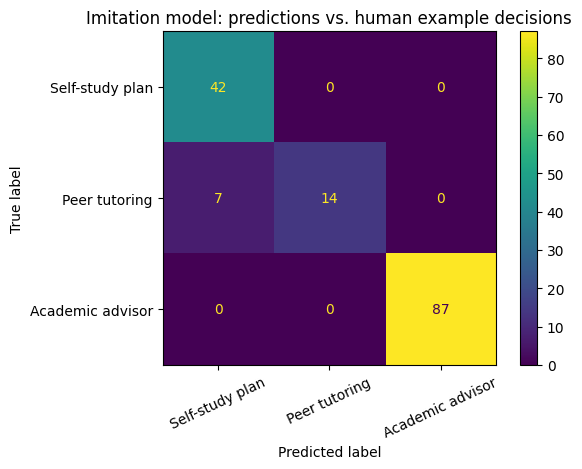

In [ ]:
FEATURES = ["attendance", "assignment_avg", "quiz_avg", "study_hours"]
TARGET = "human_decision"

X = df[FEATURES]
y = df[TARGET]
groups = df["group"]

X_train, X_test, y_train, y_test, group_train, group_test = train_test_split(
    X, y, groups, test_size=0.25, random_state=SEED, stratify=y
)

# A shallow decision tree is chosen because it is relatively interpretable.
imitation_model = Pipeline([
    ("scale", StandardScaler()),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=8, random_state=SEED))
])
imitation_model.fit(X_train, y_train)

y_pred = imitation_model.predict(X_test)
print(f"Imitation model accuracy vs. held-out human labels: {accuracy_score(y_test, y_pred):.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=ACTIONS, xticks_rotation=25
)
plt.title("Imitation model: predictions vs. human example decisions")
plt.tight_layout()
plt.show()


**Interpretation:** Accuracy measures how often the model reproduces the held-out human labels. High accuracy means it imitates those labels well; it does **not** establish that the recommendations are educationally effective, unbiased, or ethically appropriate.


## Task 3 — Explanation facility

For the rule-based system, the explanation is the exact rule that fired and the values that triggered it. For the learned model, we can inspect the decision-tree path for an individual prediction and show global feature importance.

This makes the system more transparent than a model that only returns a label, although a decision-tree explanation is still not a guarantee that the decision is fair or correct.


Rule-based recommendation: Peer tutoring
Rule fired: R2
Explanation: R2 fired: study hours 3.0 < 4.

Imitation model recommendation: Peer tutoring
Decision-tree path:
  Node 0: scaled attendance (0.47) > threshold -0.29
  Node 2: scaled quiz_avg (-0.21) > threshold -0.85
  Node 4: scaled assignment_avg (-0.69) > threshold -1.04
  Node 6: scaled study_hours (-1.20) <= threshold -0.90
  Leaf node 7: class proportions=[0.0, 1.0, 0.0], predicted=Peer tutoring


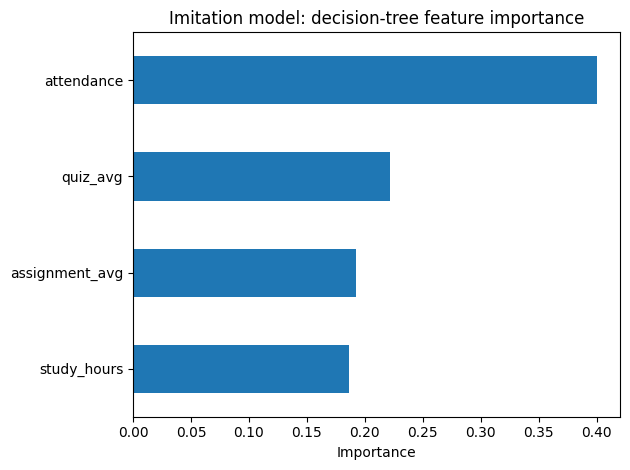

In [ ]:
# Example: explain one rule-based recommendation.
student = {
    "attendance": 78,
    "assignment_avg": 56,
    "quiz_avg": 61,
    "study_hours": 3
}
rule_result = expert_system(student)
print("Rule-based recommendation:", rule_result["recommendation"])
print("Rule fired:", rule_result["rule_id"])
print("Explanation:", rule_result["explanation"])

# Explain a learned-model prediction by following its decision-tree path.
tree = imitation_model.named_steps["tree"]
scaler = imitation_model.named_steps["scale"]
student_df = pd.DataFrame([student])[FEATURES]
student_scaled = scaler.transform(student_df)
leaf_id = tree.apply(student_scaled)[0]
node_indicator = tree.decision_path(student_scaled)
feature_names = FEATURES
tree_classes = tree.classes_

print("\nImitation model recommendation:", imitation_model.predict(student_df)[0])
print("Decision-tree path:")
for node_id in node_indicator.indices:
    if node_id == leaf_id:
        counts = tree.tree_.value[node_id][0]
        predicted_class = tree_classes[np.argmax(counts)]
        print(f"  Leaf node {node_id}: class proportions={np.round(counts, 3).tolist()}, predicted={predicted_class}")
    else:
        feature_index = tree.tree_.feature[node_id]
        if feature_index >= 0:
            threshold = tree.tree_.threshold[node_id]
            value = student_scaled[0, feature_index]
            direction = "<=" if value <= threshold else ">"
            print(
                f"  Node {node_id}: scaled {feature_names[feature_index]} "
                f"({value:.2f}) {direction} threshold {threshold:.2f}"
            )

# Global feature importance from the trained decision tree.
importance = pd.Series(
    tree.feature_importances_, index=FEATURES
).sort_values(ascending=True)
importance.plot(kind="barh")
plt.title("Imitation model: decision-tree feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()


## Task 4 — Ethical AI: group fairness and transparency audit

We compare the **recommendation rate** for each support action across the synthetic groups. If one group receives a more intensive intervention much more often, investigate why. A difference is a signal for investigation—not automatic proof of discrimination—because group sizes, underlying needs, label quality, and context matter.

We report:
- **Selection rate:** share of a group receiving each action.
- **Average support level:** simple ordinal summary (Self-study = 0, Peer tutoring = 1, Academic advisor = 2).
- **Group size:** essential context when interpreting rates.

The group field is not passed to the model. This is a limited audit on synthetic data, not a complete fairness evaluation.


Fairness audit for human-provided decisions:


,n,rate: Self-study plan,rate: Peer tutoring,rate: Academic advisor,mean_support_level
group,,,,,
Group A,68,0.324,0.088,0.588,1.265
Group B,82,0.244,0.183,0.573,1.329


Fairness audit for imitation model predictions:


,n,rate: Self-study plan,rate: Peer tutoring,rate: Academic advisor,mean_support_level
group,,,,,
Group A,68,0.338,0.074,0.588,1.250
Group B,82,0.317,0.110,0.573,1.256


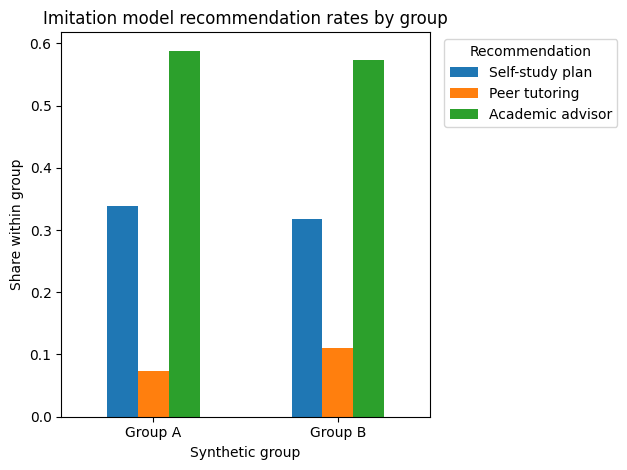

In [ ]:
SUPPORT_LEVEL = {
    "Self-study plan": 0,
    "Peer tutoring": 1,
    "Academic advisor": 2
}

audit = X_test.copy()
audit["group"] = group_test.to_numpy()
audit["human_decision"] = y_test.to_numpy()
audit["model_decision"] = y_pred

def fairness_summary(data, decision_col):
    """Summarize group-level decision rates and mean support intensity."""
    counts = data.groupby("group").size().rename("n")
    rates = pd.crosstab(data["group"], data[decision_col], normalize="index")
    rates = rates.reindex(columns=ACTIONS, fill_value=0)
    rates.columns = [f"rate: {c}" for c in rates.columns]
    support = data.assign(
        support_level=data[decision_col].map(SUPPORT_LEVEL)
    ).groupby("group")["support_level"].mean().rename("mean_support_level")
    return pd.concat([counts, rates, support], axis=1).round(3)

print("Fairness audit for human-provided decisions:")
display(fairness_summary(audit, "human_decision"))

print("Fairness audit for imitation model predictions:")
display(fairness_summary(audit, "model_decision"))

# Visual comparison of model action rates by group.
rates = pd.crosstab(audit["group"], audit["model_decision"], normalize="index")
rates = rates.reindex(columns=ACTIONS, fill_value=0)
rates.plot(kind="bar")
plt.title("Imitation model recommendation rates by group")
plt.ylabel("Share within group")
plt.xlabel("Synthetic group")
plt.xticks(rotation=0)
plt.legend(title="Recommendation", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### What should be discussed in the report?

1. Are the action rates similar across Group A and Group B?
2. If they differ, could the difference be related to the intentionally biased example labels, differences in input distributions, or model errors?
3. Why is excluding `group` from the features not enough to guarantee fairness?
4. Why should a student be able to understand and question a recommendation?
5. What additional checks would be needed before real-world use?

**Ethical safeguards:** do not use sensitive group membership to penalize students; review recommendations with a qualified person; explain how data are used; check for missing data and measurement errors; and monitor outcomes over time.


## Task 5 — Testing and comparison: change a rule and the human examples

We now test two changes:

- **Rule change:** lower the low-attendance threshold from 65% to 60% (a student at 62% attendance may no longer automatically trigger R1).
- **Example-label change:** regenerate the human decisions without the deliberate group-dependent adjustment.

Then we compare:
1. How many rule-based recommendations changed?
2. How much the learned model's agreement with the new example labels changes.
3. Whether the group recommendation-rate gap changes.

Changing the data or rules can improve one metric while worsening another. Always inspect individual cases and the reasons behind changes.


In [ ]:
# Make a modified rule-based engine. Keep the same inference structure,
# but change R1 attendance threshold from 65 to 60.
def expert_system_v2(row):
    attendance = float(row["attendance"])
    assignment_avg = float(row["assignment_avg"])
    quiz_avg = float(row["quiz_avg"])
    study_hours = float(row["study_hours"])
    score = 0.30 * attendance + 0.35 * assignment_avg + 0.35 * quiz_avg

    if attendance < 60 or assignment_avg < 50 or quiz_avg < 50:
        return {"recommendation": "Academic advisor", "rule_id": "R1-v2"}
    if score < 62 or study_hours < 4:
        return {"recommendation": "Peer tutoring", "rule_id": "R2"}
    return {"recommendation": "Self-study plan", "rule_id": "R3"}

# Apply both expert-system versions to the same test cases.
comparison = X_test.copy().reset_index(drop=True)
comparison["old_rule"] = comparison.apply(
    lambda r: expert_system(r)["recommendation"], axis=1
)
comparison["new_rule"] = comparison.apply(
    lambda r: expert_system_v2(r)["recommendation"], axis=1
)
comparison["rule_changed"] = comparison["old_rule"] != comparison["new_rule"]

print("Rule-based change count:")
print(comparison["rule_changed"].value_counts().rename(index={True: "Changed", False: "Unchanged"}))
display(comparison.loc[comparison["rule_changed"]].head(10))

# Generate a less biased example set. The revised labels use academic indicators only.
df_revised = df.copy()
df_revised["human_decision_revised"] = df_revised.apply(
    lambda r: human_label(
        r.attendance, r.assignment_avg, r.quiz_avg, r.study_hours, r.group, biased=False
    ),
    axis=1
)

# Train a second model on revised human labels using the same split indices.
X_train2 = df_revised.loc[X_train.index, FEATURES]
y_train2 = df_revised.loc[X_train.index, "human_decision_revised"]
X_test2 = df_revised.loc[X_test.index, FEATURES]
y_test2 = df_revised.loc[X_test.index, "human_decision_revised"]

revised_model = Pipeline([
    ("scale", StandardScaler()),
    ("tree", DecisionTreeClassifier(max_depth=4, min_samples_leaf=8, random_state=SEED))
])
revised_model.fit(X_train2, y_train2)
revised_pred = revised_model.predict(X_test2)

print(f"Original model agreement with original labels: {accuracy_score(y_test, y_pred):.3f}")
print(f"Revised model agreement with revised labels:   {accuracy_score(y_test2, revised_pred):.3f}")

# Compare fairness summaries on the same test cases.
fairness_compare = pd.DataFrame({
    "group": group_test.to_numpy(),
    "original_label": y_test.to_numpy(),
    "revised_label": y_test2.to_numpy(),
    "original_model": y_pred,
    "revised_model": revised_pred
})

print("\nOriginal model recommendation rates:")
display(fairness_summary(
    fairness_compare.rename(columns={"original_model": "decision"}), "decision"
))
print("Revised model recommendation rates:")
display(fairness_summary(
    fairness_compare.rename(columns={"revised_model": "decision"}), "decision"
))


Rule-based change count:
rule_changed
Unchanged    143
Changed        7
Name: count, dtype: int64


,attendance,assignment_avg,quiz_avg,study_hours,old_rule,new_rule,rule_changed
6,64,82.1,82.8,2.0,Academic advisor,Peer tutoring,True
18,62,72.0,76.0,7.9,Academic advisor,Self-study plan,True
35,62,72.2,66.7,6.1,Academic advisor,Self-study plan,True
67,62,92.4,62.3,3.9,Academic advisor,Peer tutoring,True
69,61,78.8,73.1,7.9,Academic advisor,Self-study plan,True
94,64,62.3,85.2,7.9,Academic advisor,Self-study plan,True
101,63,62.2,69.1,2.2,Academic advisor,Peer tutoring,True


Original model agreement with original labels: 0.953
Revised model agreement with revised labels:   0.967

Original model recommendation rates:


,n,rate: Self-study plan,rate: Peer tutoring,rate: Academic advisor,mean_support_level
group,,,,,
Group A,68,0.338,0.074,0.588,1.250
Group B,82,0.317,0.110,0.573,1.256


Revised model recommendation rates:


,n,rate: Self-study plan,rate: Peer tutoring,rate: Academic advisor,mean_support_level
group,,,,,
Group A,68,0.338,0.044,0.618,1.279
Group B,82,0.317,0.085,0.598,1.280


## Optional extension — inspect one changed decision

This final cell searches for a student whose recommendation changed after the attendance threshold was modified. If none exists in the current test split, it checks the full dataset. Use the printed case to explain the rule change in your viva.


In [ ]:
changed = comparison[comparison["rule_changed"]]
if len(changed) > 0:
    case = changed.iloc[0]
    print("Example where the rule change matters:")
    print(case[FEATURES].to_dict())
    print("Before:", case["old_rule"])
    print("After: ", case["new_rule"])
    print("Reason: the attendance threshold in R1 changed from <65 to <60.")
else:
    print("No changed test example in this split. Trying a targeted case:")
    targeted = {
        "attendance": 62,
        "assignment_avg": 70,
        "quiz_avg": 68,
        "study_hours": 6
    }
    print("Inputs:", targeted)
    print("Before:", expert_system(targeted)["recommendation"])
    print("After: ", expert_system_v2(targeted)["recommendation"])


Example where the rule change matters:
{'attendance': 64, 'assignment_avg': 82.1, 'quiz_avg': 82.8, 'study_hours': 2.0}
Before: Academic advisor
After:  Peer tutoring
Reason: the attendance threshold in R1 changed from <65 to <60.


## Conclusion / result

In this experiment, we built a student-support decision support prototype with:
- a transparent rule-based expert system,
- an imitation-learning classifier trained on example human decisions,
- explanations for rule firing and decision-tree paths,
- a group-based fairness audit,
- and a before/after comparison after modifying a rule and the example labels.

### Important limitation
The data and labels are synthetic and designed for teaching. Model accuracy only measures imitation of the supplied labels. Fairness metrics are diagnostic, and no single metric proves a system is fair. A real deployment would require validated educational criteria, consultation with students and educators, privacy safeguards, human review, and ongoing evaluation.

### Short viva questions
1. **What is an expert system?** A system that uses a knowledge base and inference rules to produce recommendations.
2. **What is imitation learning here?** Training a model to reproduce decisions supplied as examples by a human.
3. **Why have an explanation facility?** To make the basis of a recommendation inspectable and contestable.
4. **Does high accuracy mean the system is fair?** No; it can accurately reproduce biased labels.
5. **Why audit groups if group is not a model feature?** Other features and training labels may still encode group-related patterns.
6. **Why compare before and after changes?** To see how rule thresholds or example decisions affect outputs, accuracy, and group-level outcomes.
